# Gláucio Soares da Silva  

**Modelo de reconhecimento facial, utilizando o dataset CelebA ~212 mil imagens, com extração de características com os métodos HOG e BLP e para predição com SVM e Regressão Logística, um método comparativo.**

  


Carregando set de 15% das amostras com Filtro de >= 30 imagens por ID

In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path(r"C:\Users\Glaucio\Documents\image converter\CelebA")
OUT = ROOT / "out"
OUT.mkdir(parents=True, exist_ok=True)

ID_TXT = ROOT / "identity_CelebA.txt"

MIN_IMGS = 30
FRAC_TOTAL = 0.15  # 15% do total de imagens

OUT_CSV = OUT / "set15pct_idsinteiros_ge30.csv"

# 1) Lê identity
rows = []
with open(ID_TXT, "r", encoding="utf-8", errors="ignore") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        fn, id_str = line.split()
        rows.append((fn, int(id_str)))

df = pd.DataFrame(rows, columns=["file", "id"])
N_total = len(df)
target = int(round(N_total * FRAC_TOTAL))

# Filtra IDs elegíveis (>=30) e ordena do maior para menor
counts = df["id"].value_counts()
eligible = counts[counts >= MIN_IMGS]
if len(eligible) == 0:
    raise SystemExit(f"Nenhum ID com >= {MIN_IMGS} imagens.")

# Seleciona IDs inteiros até bater ~15% do total
sel_ids = []
acc = 0
for id_, c in eligible.items():
    if acc < target:
        sel_ids.append(int(id_))
        acc += int(c)
    else:
        break

# Ajuste fino: remove o último ID se aproximar mais do target
if len(sel_ids) >= 2:
    last = sel_ids[-1]
    acc_without_last = acc - int(eligible[last])
    if abs(target - acc_without_last) < abs(target - acc):
        sel_ids.pop()
        acc = acc_without_last

mf = df[df["id"].isin(sel_ids)].copy().reset_index(drop=True)
mf.to_csv(OUT_CSV, index=False)

print("========================================")
print("Total de imagens:", N_total)
print("Target (15%):", target)
print("IDs elegíveis (>=30):", len(eligible))
print("IDs selecionados:", len(sel_ids))
print("Imagens selecionadas:", len(mf))
print("Diferença p/ target:", len(mf) - target)
print("Min por ID no subset:", int(mf["id"].value_counts().min()))
print("Salvo em:", OUT_CSV)
print("========================================")


Total de imagens: 202599
Target (15%): 30390
IDs elegíveis (>=30): 2360
IDs selecionados: 1012
Imagens selecionadas: 30398
Diferença p/ target: 8
Min por ID no subset: 30
Salvo em: C:\Users\Glaucio\Documents\image converter\CelebA\out\set15pct_idsinteiros_ge30.csv


Extrair HOG e BLP

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm import tqdm

from skimage import io
from skimage.transform import resize
from skimage.feature import hog, local_binary_pattern

ROOT = Path(r"C:\Users\Glaucio\Documents\image converter\CelebA")
OUT  = ROOT / "out"

#pasta das imagens
IMG_DIR = ROOT / "img_align_celeba/img_align_celeba"

MANIFEST = OUT / "set15pct_idsinteiros_ge30.csv"
FEAT_DIR = OUT / "features"
FEAT_DIR.mkdir(parents=True, exist_ok=True)

#uso.dat (memmap robusto)
X_OUT = FEAT_DIR / "X_hog_lbp_set15pct_idsinteiros_ge30.dat"

HOG_COLS = 1764
LBP_COLS = 18
FEAT_DIM = HOG_COLS + LBP_COLS

# HOG parametros
HOG_ORI = 9
PPC = (8, 8)
CPB = (2, 2)

# LBP parametros
radius = 2
n_points = 8 * radius

# ---------- checagenss ----------
print("MANIFEST:", MANIFEST)
print("IMG_DIR :", IMG_DIR)
print("FEAT_DIR:", FEAT_DIR)
print("X_OUT   :", X_OUT)

if not MANIFEST.exists():
    raise SystemExit(f"Manifest não encontrado: {MANIFEST}")

if not IMG_DIR.exists():
    raise SystemExit(
        f"IMG_DIR não existe: {IMG_DIR}\n"
        "Corrija IMG_DIR para apontar para a pasta correta das imagens."
    )

mf = pd.read_csv(MANIFEST)

#auto-detecta coluna do filename (caso não seja 'file')
if "file" not in mf.columns:

    cand = None
    for c in mf.columns:
        if mf[c].astype(str).str.contains(r"\.jpg", case=False, regex=True).mean() > 0.5:
            cand = c
            break
    if cand is None:
        raise SystemExit(f"Não achei coluna de arquivo no manifest. Colunas: {mf.columns.tolist()}")
    mf = mf.rename(columns={cand: "file"})

files = mf["file"].astype(str).tolist()


if X_OUT.exists():
    try:
        X_OUT.unlink()
        print("Arquivo antigo removido:", X_OUT)
    except Exception as e:
        raise SystemExit(
            f"Não consegui remover o arquivo antigo: {X_OUT}\n"
            f"Feche notebooks/programas que estejam usando esse arquivo e tente de novo.\n"
            f"Erro: {e}"
        )

print("Imagens no manifest:", len(files))
print("Criando memmap...")

#cria memmap binário cru
X = np.memmap(str(X_OUT), dtype=np.float32, mode="w+", shape=(len(files), FEAT_DIM))

for i, fn in enumerate(tqdm(files, desc="HOG+LBP")):
    p = IMG_DIR / fn
    if not p.exists():
        raise FileNotFoundError(f"Imagem não encontrada: {p}")

    img = io.imread(str(p))
    if img.ndim == 3:
        img = img[..., 0]

    img = resize(img, (64, 64), anti_aliasing=True)
    img = (img * 255).astype(np.uint8)

    fh = hog(
        img,
        orientations=HOG_ORI,
        pixels_per_cell=PPC,
        cells_per_block=CPB,
        block_norm="L2-Hys",
        feature_vector=True
    ).astype(np.float32)

    lbp = local_binary_pattern(img, n_points, radius, method="uniform")
    hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, LBP_COLS + 1), range=(0, LBP_COLS))
    hist = (hist / (hist.sum() + 1e-12)).astype(np.float32)

    X[i, :HOG_COLS] = fh
    X[i, HOG_COLS:] = hist

X.flush()
print("Features salvas em:", X_OUT)
print("Shape:", X.shape)

# salva um npz pequeno com metadados
meta = FEAT_DIR / "X_hog_lbp_set15pct_idsinteiros_ge30_meta.npz"
np.savez(meta, n=len(files), feat_dim=FEAT_DIM, hog_cols=HOG_COLS, lbp_cols=LBP_COLS)
print("Meta salvo em:", meta)


MANIFEST: C:\Users\Glaucio\Documents\image converter\CelebA\out\set15pct_idsinteiros_ge30.csv
IMG_DIR : C:\Users\Glaucio\Documents\image converter\CelebA\img_align_celeba\img_align_celeba
FEAT_DIR: C:\Users\Glaucio\Documents\image converter\CelebA\out\features
X_OUT   : C:\Users\Glaucio\Documents\image converter\CelebA\out\features\X_hog_lbp_set15pct_idsinteiros_ge30.dat
Arquivo antigo removido: C:\Users\Glaucio\Documents\image converter\CelebA\out\features\X_hog_lbp_set15pct_idsinteiros_ge30.dat
Imagens no manifest: 30398
Criando memmap...


HOG+LBP: 100%|██████████| 30398/30398 [07:42<00:00, 65.71it/s]  


Features salvas em: C:\Users\Glaucio\Documents\image converter\CelebA\out\features\X_hog_lbp_set15pct_idsinteiros_ge30.dat
Shape: (30398, 1782)
Meta salvo em: C:\Users\Glaucio\Documents\image converter\CelebA\out\features\X_hog_lbp_set15pct_idsinteiros_ge30_meta.npz


Leitura do Dataset criado com extrações do HOG e BLP

In [ ]:
ROOT = Path(r"C:\Users\Glaucio\Documents\image converter\CelebA")
OUT  = ROOT / "out"

MANIFEST = OUT / "set15pct_idsinteiros_ge30.csv"
X_PATH   = OUT / "features" / "X_hog_lbp_set15pct_idsinteiros_ge30.dat"

mf = pd.read_csv(MANIFEST)
n = len(mf)

HOG_COLS = 1764
LBP_COLS = 18
FEAT_DIM = HOG_COLS + LBP_COLS

X_all = np.memmap(X_PATH, dtype=np.float32, mode="r", shape=(n, FEAT_DIM))
X_hog = X_all[:, :HOG_COLS]
X_lbp = X_all[:, HOG_COLS:HOG_COLS + LBP_COLS]

y_ids = mf["id"].to_numpy(np.int32)

print("n:", n)
print("X_all:", X_all.shape)
print("IDs únicos:", mf["id"].nunique())


n: 30398
X_all: (30398, 1782)
IDs únicos: 1012


Escolher ID alvo e montar y binário + histograma (diagnóstico)

id_alvo: 2820
pos: 35 neg: 30363
min por ID no subset: 30


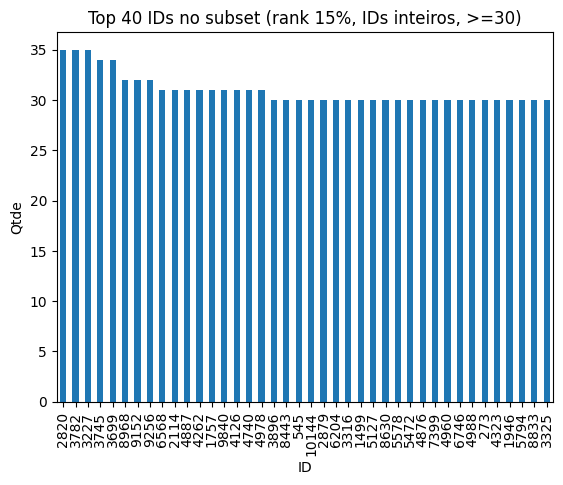

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

vc = pd.Series(y_ids).value_counts()
id_alvo = int(vc.index[0])
y_bin = (y_ids == id_alvo).astype(np.int32)

print("id_alvo:", id_alvo)
print("pos:", int((y_bin==1).sum()), "neg:", int((y_bin==0).sum()))
print("min por ID no subset:", int(vc.min()))

plt.figure()
vc.head(40).plot(kind="bar")
plt.title("Top 40 IDs no subset (rank 15%, IDs inteiros, >=30)")
plt.xlabel("ID")
plt.ylabel("Qtde")
plt.show()


Métricas, subamostragem, threshold na validação

In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    roc_auc_score, balanced_accuracy_score, confusion_matrix
)

def metricas_autenticacao(y_true, prob_pos, thr=0.5):
    y_pred = (prob_pos >= thr).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    far = fp / (fp + tn + 1e-12)
    frr = fn / (fn + tp + 1e-12)
    auc = roc_auc_score(y_true, prob_pos) if len(np.unique(y_true)) == 2 else float("nan")

    return {
        "auc": float(auc),
        "acuracia": float(accuracy_score(y_true, y_pred)),
        "balanced_acc": float(balanced_accuracy_score(y_true, y_pred)),
        "precisao": float(precision_score(y_true, y_pred, zero_division=0)),
        "revocacao": float(recall_score(y_true, y_pred, zero_division=0)),
        "far": float(far),
        "frr": float(frr),
        "cm": cm
    }

def subamostrar_negativos(X, y, ratio_neg=30, seed=42):
    rng = np.random.default_rng(seed)
    pos_idx = np.where(y == 1)[0]
    neg_idx = np.where(y == 0)[0]
    if len(pos_idx) == 0:
        raise ValueError("Sem positivos nesse split.")
    n_neg = min(len(neg_idx), ratio_neg * len(pos_idx))
    neg_sel = rng.choice(neg_idx, size=n_neg, replace=False)
    idx = np.concatenate([pos_idx, neg_sel])
    rng.shuffle(idx)
    return X[idx], y[idx]

def escolher_threshold_validacao(y_va, prob_va):
    ths = np.linspace(0.01, 0.99, 99)
    best_t, best_ba = 0.5, -1
    for t in ths:
        m = metricas_autenticacao(y_va, prob_va, thr=t)
        if m["balanced_acc"] > best_ba:
            best_ba = m["balanced_acc"]
            best_t = t
    return best_t, best_ba


Treino por épocas (SGD LogReg / SGD SVM) com regularização L2

In [ ]:
from sklearn.linear_model import SGDClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import log_loss

def treinar_por_epocas_sgd_balanceado(
    Xtr, ytr, Xva, yva, Xte, yte,
    modo="logreg", epocas=220, lr0=0.01, alpha=1e-4, seed=42
):
    if modo == "logreg":
        loss = "log_loss"
    elif modo == "svm":
        loss = "hinge"
    else:
        raise ValueError("modo inválido (use 'logreg' ou 'svm')")

    classes = np.array([0, 1], dtype=np.int32)
    w = compute_class_weight("balanced", classes=classes, y=ytr)
    cw = {0: float(w[0]), 1: float(w[1])}

    clf = SGDClassifier(
        loss=loss,
        penalty="l2",
        alpha=alpha,
        learning_rate="constant",
        eta0=lr0,
        random_state=seed,
        class_weight=cw
    )

    hist = {"epoca": [], "loss_treino": [], "loss_valid": [], "loss_teste": [],
            "erro_treino": [], "erro_valid": [], "erro_teste": []}

    def prob_pos(X):
        s = clf.decision_function(X)
        return 1 / (1 + np.exp(-s))

    for ep in range(epocas):
        clf.partial_fit(Xtr, ytr, classes=classes)

        p_tr = prob_pos(Xtr)
        p_va = prob_pos(Xva)
        p_te = prob_pos(Xte)

        lt  = log_loss(ytr, p_tr, labels=[0,1])
        lv  = log_loss(yva, p_va, labels=[0,1])
        lte = log_loss(yte, p_te, labels=[0,1])

        et  = 1 - accuracy_score(ytr, (p_tr >= 0.5).astype(int))
        ev  = 1 - accuracy_score(yva, (p_va >= 0.5).astype(int))
        ete = 1 - accuracy_score(yte, (p_te >= 0.5).astype(int))

        hist["epoca"].append(ep)
        hist["loss_treino"].append(float(lt))
        hist["loss_valid"].append(float(lv))
        hist["loss_teste"].append(float(lte))
        hist["erro_treino"].append(float(et))
        hist["erro_valid"].append(float(ev))
        hist["erro_teste"].append(float(ete))

    return clf, hist, prob_pos(Xte)


K-fold com balanceamento e threshold na validação

In [ ]:
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler

def avaliar_kfold_autenticacao(
    X, y, modo, k=5, ratio_neg=30,
    epocas=220, lr0=0.01, alpha=1e-4, seed=42
):
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    mets = []

    for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y), 1):
        X_tr, X_te = X[tr_idx], X[te_idx]
        y_tr, y_te = y[tr_idx], y[te_idx]

        X_tr, X_va, y_tr, y_va = train_test_split(
            X_tr, y_tr, test_size=0.2, random_state=seed, stratify=y_tr
        )

        sc = StandardScaler()
        X_tr = sc.fit_transform(X_tr)
        X_va = sc.transform(X_va)
        X_te = sc.transform(X_te)

        X_tr_b, y_tr_b = subamostrar_negativos(X_tr, y_tr, ratio_neg=ratio_neg, seed=seed + fold)
        X_va_b, y_va_b = subamostrar_negativos(X_va, y_va, ratio_neg=ratio_neg, seed=seed + 100 + fold)

        clf, hist, prob_te = treinar_por_epocas_sgd_balanceado(
            X_tr_b, y_tr_b, X_va_b, y_va_b, X_te, y_te,
            modo=modo, epocas=epocas, lr0=lr0, alpha=alpha, seed=seed + fold
        )

        prob_va = 1 / (1 + np.exp(-clf.decision_function(X_va_b)))
        thr, _ = escolher_threshold_validacao(y_va_b, prob_va)

        met = metricas_autenticacao(y_te, prob_te, thr=thr)
        met["thr_val"] = float(thr)
        mets.append(met)

    keys = ["auc","balanced_acc","acuracia","precisao","revocacao","far","frr","thr_val"]
    return {k: float(np.mean([m[k] for m in mets])) for k in keys}


Rodar 4 cenários + tabela final

In [ ]:
param_log = dict(epocas=240, lr0=0.02, alpha=1e-4)
param_svm = dict(epocas=240, lr0=0.01, alpha=1e-4)
ratio_neg = 30

res_hog_svm = avaliar_kfold_autenticacao(X_hog, y_bin, modo="svm",   k=5, ratio_neg=ratio_neg, **param_svm)
res_hog_log = avaliar_kfold_autenticacao(X_hog, y_bin, modo="logreg",k=5, ratio_neg=ratio_neg, **param_log)
res_lbp_svm = avaliar_kfold_autenticacao(X_lbp, y_bin, modo="svm",   k=5, ratio_neg=ratio_neg, **param_svm)
res_lbp_log = avaliar_kfold_autenticacao(X_lbp, y_bin, modo="logreg",k=5, ratio_neg=ratio_neg, **param_log)

df_final = pd.DataFrame([
    {"Extrator":"HOG","Classificador":"SVM","AUC":res_hog_svm["auc"],"BalAcc":res_hog_svm["balanced_acc"],"FAR":res_hog_svm["far"],"FRR":res_hog_svm["frr"]},
    {"Extrator":"HOG","Classificador":"Regressão Logística","AUC":res_hog_log["auc"],"BalAcc":res_hog_log["balanced_acc"],"FAR":res_hog_log["far"],"FRR":res_hog_log["frr"]},
    {"Extrator":"LBP","Classificador":"SVM","AUC":res_lbp_svm["auc"],"BalAcc":res_lbp_svm["balanced_acc"],"FAR":res_lbp_svm["far"],"FRR":res_lbp_svm["frr"]},
    {"Extrator":"LBP","Classificador":"Regressão Logística","AUC":res_lbp_log["auc"],"BalAcc":res_lbp_log["balanced_acc"],"FAR":res_lbp_log["far"],"FRR":res_lbp_log["frr"]},
]).sort_values(by=["AUC","BalAcc"], ascending=False)

display(df_final)


,Extrator,Classificador,AUC,BalAcc,FAR,FRR
1,HOG,Regressão Logística,0.645500,0.533249,0.276358,0.657143
0,HOG,SVM,0.635947,0.591935,0.301844,0.514286
3,LBP,Regressão Logística,0.542425,0.560888,0.278225,0.600000
2,LBP,SVM,0.530292,0.484477,0.431047,0.600000


Gerar artefatos (Hog/Blp Melhor/Pior)

In [ ]:
import time, pickle
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from pathlib import Path

ARTEFATOS = OUT / "artefatos"
ARTEFATOS.mkdir(parents=True, exist_ok=True)

def escreve_config(pasta: Path, params: dict):
    pasta.mkdir(parents=True, exist_ok=True)
    p = pasta / "config.txt"
    with open(p, "w", encoding="utf-8") as f:
        f.write(f"Execução em: {time.strftime('%d/%m/%Y %H:%M:%S')}\n\n")
        for k, v in params.items():
            f.write(f"{k}: {v}\n")
    return p

def escreve_error(pasta: Path, hist: dict):
    p = pasta / "error.txt"
    with open(p, "w", encoding="utf-8") as f:
        f.write("epoca;loss_treino;loss_valid;loss_teste;erro_treino;erro_valid;erro_teste\n")
        for i in range(len(hist["epoca"])):
            f.write(
                f"{hist['epoca'][i]};"
                f"{hist['loss_treino'][i]:.6f};{hist['loss_valid'][i]:.6f};{hist['loss_teste'][i]:.6f};"
                f"{hist['erro_treino'][i]:.6f};{hist['erro_valid'][i]:.6f};{hist['erro_teste'][i]:.6f}\n"
            )
    return p

def escreve_model(pasta: Path, pack: dict):
    p = pasta / "model.dat"
    with open(p, "wb") as f:
        pickle.dump(pack, f)
    return p

def split_padroniza(X, y, seed=42):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    X_tr, X_va, y_tr, y_va = train_test_split(X_tr, y_tr, test_size=0.2, random_state=seed, stratify=y_tr)
    sc = StandardScaler()
    X_tr = sc.fit_transform(X_tr)
    X_va = sc.transform(X_va)
    X_te = sc.transform(X_te)
    return X_tr, y_tr, X_va, y_va, X_te, y_te, sc

def treina_duas_e_exporta(nome_descritor, X, y, pasta_base, ratio_neg=30):
    X_tr, y_tr, X_va, y_va, X_te, y_te, sc = split_padroniza(X, y, seed=42)

    X_tr_b, y_tr_b = subamostrar_negativos(X_tr, y_tr, ratio_neg=ratio_neg, seed=1)
    X_va_b, y_va_b = subamostrar_negativos(X_va, y_va, ratio_neg=ratio_neg, seed=2)

    params_log = dict(epocas=240, lr0=0.02, alpha=1e-4, seed=7)
    params_svm = dict(epocas=240, lr0=0.01, alpha=1e-4, seed=8)

    clf_log, hist_log, prob_te_log = treinar_por_epocas_sgd_balanceado(
        X_tr_b,y_tr_b,X_va_b,y_va_b,X_te,y_te,modo="logreg",**params_log
    )
    prob_va_log = 1/(1+np.exp(-clf_log.decision_function(X_va_b)))
    thr_log,_ = escolher_threshold_validacao(y_va_b, prob_va_log)
    met_log = metricas_autenticacao(y_te, prob_te_log, thr=thr_log); met_log["thr_val"]=float(thr_log)

    clf_svm, hist_svm, prob_te_svm = treinar_por_epocas_sgd_balanceado(
        X_tr_b,y_tr_b,X_va_b,y_va_b,X_te,y_te,modo="svm",**params_svm
    )
    prob_va_svm = 1/(1+np.exp(-clf_svm.decision_function(X_va_b)))
    thr_svm,_ = escolher_threshold_validacao(y_va_b, prob_va_svm)
    met_svm = metricas_autenticacao(y_te, prob_te_svm, thr=thr_svm); met_svm["thr_val"]=float(thr_svm)

    # escolhe melhor/pior por AUC
    cand = [
        ("Regressao_Logistica", clf_log, hist_log, met_log, params_log),
        ("SVM",                clf_svm, hist_svm, met_svm, params_svm),
    ]
    cand.sort(key=lambda x: x[3]["auc"], reverse=True)

    for rotulo, item in [("Melhor", cand[0]), ("Pior", cand[-1])]:
        nome_modelo, clf, hist, met, params = item
        pasta = pasta_base / rotulo

        cfg = {
            "descritor": nome_descritor,
            "classificador": nome_modelo,
            "id_alvo": int(id_alvo),
            "ratio_neg": ratio_neg,
            "regularizacao_L2_alpha": params["alpha"],
            "lr0": params["lr0"],
            "epocas": params["epocas"],
            "threshold_validacao": met["thr_val"],
            "auc_teste": met["auc"],
            "balanced_acc_teste": met["balanced_acc"],
            "far_teste": met["far"],
            "frr_teste": met["frr"],
        }

        pack = {"scaler": sc, "modelo": clf, "cfg": cfg, "metricas": met}
        escreve_config(pasta, cfg)
        escreve_error(pasta, hist)
        escreve_model(pasta, pack)

PASTA_HOG   = ARTEFATOS / "Hog"
PASTA_OUTRO = ARTEFATOS / "Outro"

treina_duas_e_exporta("HOG", X_hog, y_bin, PASTA_HOG, ratio_neg=30)
treina_duas_e_exporta("LBP", X_lbp, y_bin, PASTA_OUTRO, ratio_neg=30)

print("Artefatos em:", ARTEFATOS)


Artefatos em: C:\Users\Glaucio\Documents\image converter\CelebA\out\artefatos


Plotar curvas dos artefatos

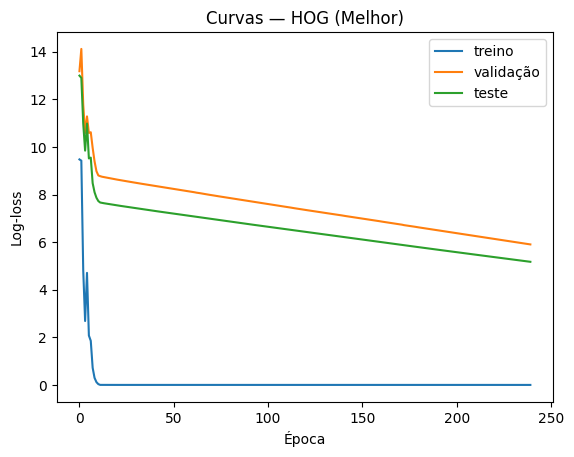

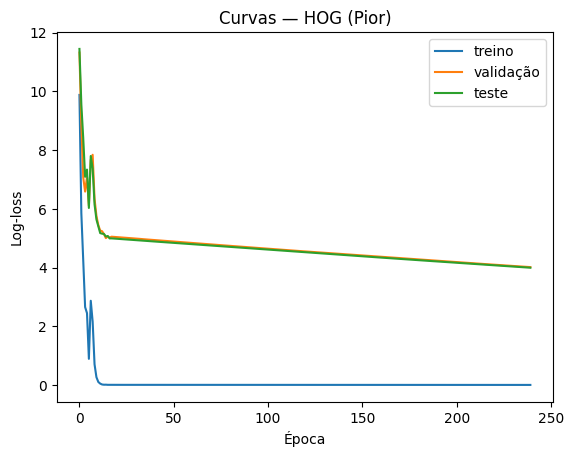

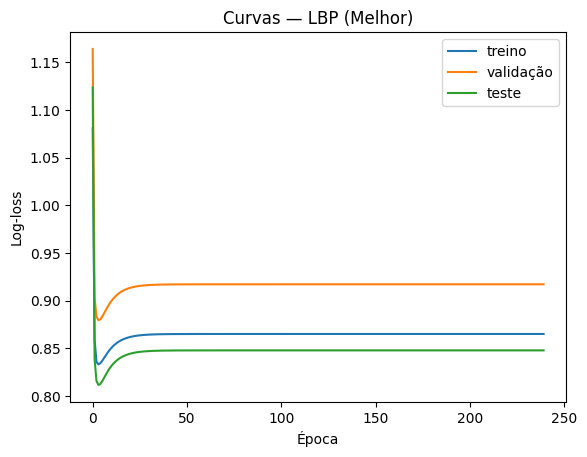

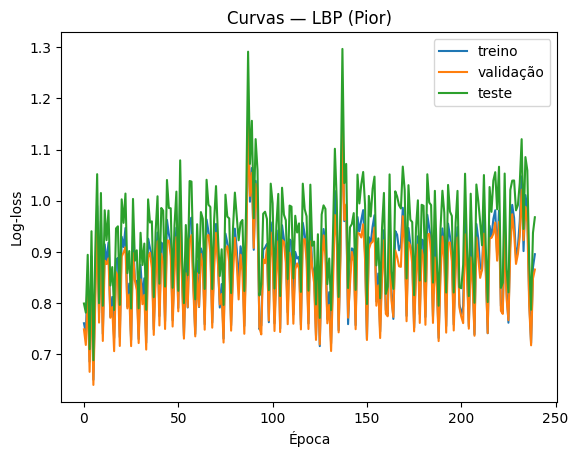

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

def plot_curvas(pasta: Path, titulo: str):
    df = pd.read_csv(pasta / "error.txt", sep=";")
    plt.figure()
    plt.plot(df["epoca"], df["loss_treino"], label="treino")
    plt.plot(df["epoca"], df["loss_valid"],  label="validação")
    plt.plot(df["epoca"], df["loss_teste"],  label="teste")
    plt.title(titulo)
    plt.xlabel("Época")
    plt.ylabel("Log-loss")
    plt.legend()
    plt.show()

plot_curvas(ARTEFATOS/"Hog"/"Melhor",   "Curvas — HOG (Melhor)")
plot_curvas(ARTEFATOS/"Hog"/"Pior",     "Curvas — HOG (Pior)")
plot_curvas(ARTEFATOS/"Outro"/"Melhor", "Curvas — LBP (Melhor)")
plot_curvas(ARTEFATOS/"Outro"/"Pior",   "Curvas — LBP (Pior)")


Conferência final dos arquivos

In [ ]:
print("Arquivos gerados em", ARTEFATOS)
for p in ARTEFATOS.rglob("*"):
    if p.is_file():
        print(" -", p.relative_to(ARTEFATOS))


Arquivos gerados em C:\Users\Glaucio\Documents\image converter\CelebA\out\artefatos
 - Hog\Melhor\config.txt
 - Hog\Melhor\error.txt
 - Hog\Melhor\model.dat
 - Hog\Pior\config.txt
 - Hog\Pior\error.txt
 - Hog\Pior\model.dat
 - Outro\Melhor\config.txt
 - Outro\Melhor\error.txt
 - Outro\Melhor\model.dat
 - Outro\Pior\config.txt
 - Outro\Pior\error.txt
 - Outro\Pior\model.dat
